In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
dataset = pd.read_csv('Mall_Customers.csv')

In [3]:
dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [4]:
X = dataset.iloc[:, 3:5].values

In [5]:
X

array([[ 15,  39],
       [ 15,  81],
       [ 16,   6],
       [ 16,  77],
       [ 17,  40],
       [ 17,  76],
       [ 18,   6],
       [ 18,  94],
       [ 19,   3],
       [ 19,  72],
       [ 19,  14],
       [ 19,  99],
       [ 20,  15],
       [ 20,  77],
       [ 20,  13],
       [ 20,  79],
       [ 21,  35],
       [ 21,  66],
       [ 23,  29],
       [ 23,  98],
       [ 24,  35],
       [ 24,  73],
       [ 25,   5],
       [ 25,  73],
       [ 28,  14],
       [ 28,  82],
       [ 28,  32],
       [ 28,  61],
       [ 29,  31],
       [ 29,  87],
       [ 30,   4],
       [ 30,  73],
       [ 33,   4],
       [ 33,  92],
       [ 33,  14],
       [ 33,  81],
       [ 34,  17],
       [ 34,  73],
       [ 37,  26],
       [ 37,  75],
       [ 38,  35],
       [ 38,  92],
       [ 39,  36],
       [ 39,  61],
       [ 39,  28],
       [ 39,  65],
       [ 40,  55],
       [ 40,  47],
       [ 40,  42],
       [ 40,  42],
       [ 42,  52],
       [ 42,  60],
       [ 43,

In [6]:
from sklearn.cluster import DBSCAN
X = np.random.rand(100, 2)
num_clusters_list = []
eps_range = np.linspace(0.05, 0.5, 10)
for eps in eps_range:
    dbscan = DBSCAN(eps=eps, min_samples=5)  
    dbscan.fit(X)
    num_clusters = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
    num_clusters_list.append(num_clusters)

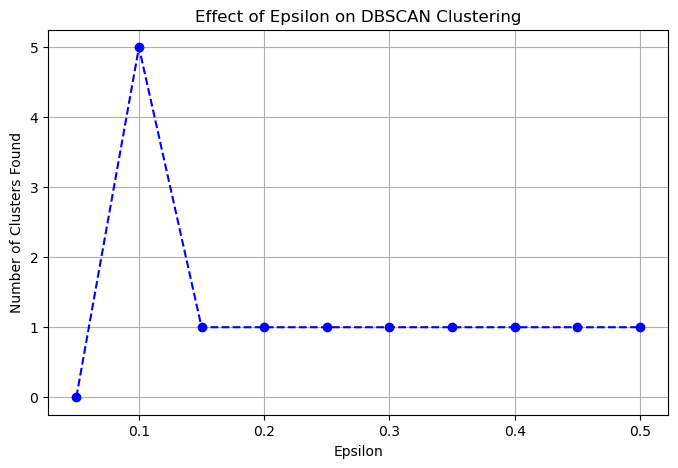

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(eps_range, num_clusters_list, marker='o', linestyle='--', color='b')
plt.title('Effect of Epsilon on DBSCAN Clustering')
plt.xlabel('Epsilon')
plt.ylabel('Number of Clusters Found')
plt.grid(True)
plt.show()

In [8]:
num_clusters_list

[0, 5, 1, 1, 1, 1, 1, 1, 1, 1]

In [9]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
X, _ = make_blobs(n_samples=200, centers=4, cluster_std=0.60, random_state=42)
dbscan = DBSCAN(eps=0.2, min_samples=5)  
y_dbscan = dbscan.fit_predict(X)

In [10]:
y_dbscan

array([-1, -1,  1, -1,  0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1,  1, -1,  4, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1,  1, -1,  1, -1, -1,  3, -1, -1, -1, -1, -1,  2, -1, -1, -1,
        3, -1, -1, -1, -1, -1, -1,  3, -1,  4, -1, -1,  1, -1,  2, -1, -1,
        4, -1, -1, -1, -1,  0, -1, -1, -1, -1, -1,  3, -1, -1, -1,  4, -1,
        4, -1, -1, -1, -1,  2, -1, -1, -1, -1, -1,  3,  5, -1, -1, -1, -1,
       -1,  2, -1, -1, -1,  0, -1, -1,  5, -1, -1,  4, -1, -1, -1, -1, -1,
       -1, -1, -1, -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1,  5, -1, -1,  4, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1,  5, -1, -1, -1, -1, -1,  2,  5,
       -1, -1,  0,  2, -1, -1, -1,  3, -1, -1,  3, -1,  1, -1, -1, -1,  5,
        5, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  0, -1])

In [11]:
supervised=dataset

In [12]:
supervised['Cluster_group']=y_dbscan

In [13]:
supervised

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster_group
0,1,Male,19,15,39,-1
1,2,Male,21,15,81,-1
2,3,Female,20,16,6,1
3,4,Female,23,16,77,-1
4,5,Female,31,17,40,0
...,...,...,...,...,...,...
195,196,Female,35,120,79,-1
196,197,Female,45,126,28,-1
197,198,Male,32,126,74,-1
198,199,Male,32,137,18,0


In [14]:
supervised.to_csv("cluster_DBSCAN_Clustering.csv", index=False)

In [15]:
supervised

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster_group
0,1,Male,19,15,39,-1
1,2,Male,21,15,81,-1
2,3,Female,20,16,6,1
3,4,Female,23,16,77,-1
4,5,Female,31,17,40,0
...,...,...,...,...,...,...
195,196,Female,35,120,79,-1
196,197,Female,45,126,28,-1
197,198,Male,32,126,74,-1
198,199,Male,32,137,18,0


In [16]:
dir(dbscan)

['__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__sklearn_tags__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_build_request_for_signature',
 '_check_feature_names',
 '_check_n_features',
 '_doc_link_module',
 '_doc_link_template',
 '_doc_link_url_param_generator',
 '_estimator_type',
 '_get_default_requests',
 '_get_doc_link',
 '_get_metadata_request',
 '_get_param_names',
 '_get_tags',
 '_more_tags',
 '_parameter_constraints',
 '_repr_html_',
 '_repr_html_inner',
 '_repr_mimebundle_',
 '_validate_data',
 '_validate_params',
 'algorithm',
 'components_',
 'core_sample_indices_',
 'eps',


In [17]:
cluster_centers = []
for label in np.unique(y_dbscan):
    if label != -1:  # Exclude noise points (label = -1)
        cluster_points = X[y_dbscan == label]  
        cluster_center = np.mean(cluster_points, axis=0)  
        cluster_centers.append(cluster_center)
cluster_centers = np.array(cluster_centers)

In [18]:
cluster_centers

array([[-7.21006592, -6.37256323],
       [-8.74208482,  6.87370687],
       [-6.80519532, -7.22468368],
       [-2.88954427,  8.84536115],
       [-8.40747942,  7.15828956],
       [ 4.79098237,  2.27657193]])

In [19]:
y_dbscan

array([-1, -1,  1, -1,  0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1,  1, -1,  4, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1,  1, -1,  1, -1, -1,  3, -1, -1, -1, -1, -1,  2, -1, -1, -1,
        3, -1, -1, -1, -1, -1, -1,  3, -1,  4, -1, -1,  1, -1,  2, -1, -1,
        4, -1, -1, -1, -1,  0, -1, -1, -1, -1, -1,  3, -1, -1, -1,  4, -1,
        4, -1, -1, -1, -1,  2, -1, -1, -1, -1, -1,  3,  5, -1, -1, -1, -1,
       -1,  2, -1, -1, -1,  0, -1, -1,  5, -1, -1,  4, -1, -1, -1, -1, -1,
       -1, -1, -1, -1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1,  5, -1, -1,  4, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1,  5, -1, -1, -1, -1, -1,  2,  5,
       -1, -1,  0,  2, -1, -1, -1,  3, -1, -1,  3, -1,  1, -1, -1, -1,  5,
        5, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  0, -1])

In [20]:
supervised.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)', 'Cluster_group'],
      dtype='object')

In [21]:
import seaborn as sns
np.random.seed(42)
supervised = pd.DataFrame({
    'CustomerID': np.arange(1, 101),
    'Age': np.random.randint(18, 70, 100),
    'Annual Income (k$)': np.random.randint(15, 140, 100),
    'Spending Score (1-100)': np.random.randint(1, 100, 100),
})
x_col = 'Annual Income (k$)'
y_col = 'Spending Score (1-100)'
dbscan = DBSCAN(eps=0.2, min_samples=5)
supervised['Cluster'] = dbscan.fit_predict(supervised[[x_col, y_col]])

C:\Anaconda 3\Lib\site-packages\seaborn\regression.py:598: UserWarning: legend_out is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


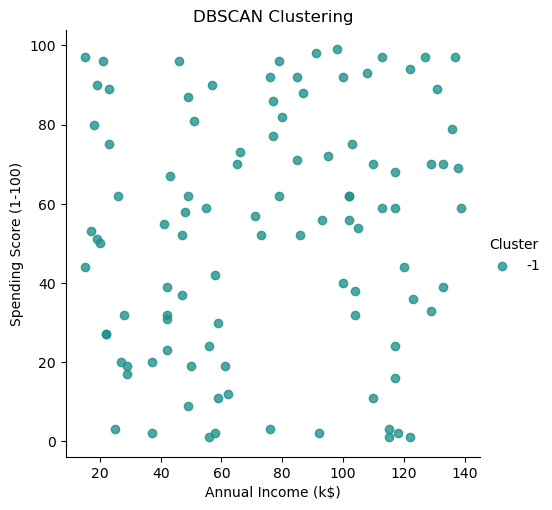

In [22]:
facet = sns.lmplot(
    data=supervised, x=x_col, y=y_col, hue='Cluster',
    fit_reg=False, legend=True, legend_out=True, palette="viridis"
)
plt.title('DBSCAN Clustering')
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.show()

In [23]:
import pickle
with open("dbscan_model.pkl", "wb") as file:
    pickle.dump(dbscan, file)
print("DBSCAN model saved successfully")

DBSCAN model saved successfully


In [24]:
with open("dbscan_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)
print("DBSCAN model loaded successfully")

DBSCAN model loaded successfully


In [25]:
core_samples = loaded_model.components_
core_labels = loaded_model.labels_[loaded_model.core_sample_indices_]
print("Number of core samples:", len(core_samples))
print("Core sample labels:", core_labels)

Number of core samples: 0
Core sample labels: []


In [26]:
new_data = np.array([[15, 39]])
if len(core_samples) == 0:
    print("No core samples found.")
else:
    distances = np.linalg.norm(core_samples - new_data, axis=1)
    nearest_cluster = np.argmin(distances)

    if distances[nearest_cluster] <= loaded_model.eps:
        result = core_labels[nearest_cluster]
    else:
        result = -1
        print("Predicted Cluster:", result)

No core samples found.
